In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.formula.api as smf

import pickle
import os

### Question 3

3. Which subscription plans are the leakiest, and are they worth saving?
Basic has the highest churn (about 81%) and Plus the lowest (about 67%), but median monthly spend differs a lot between them (about $30 for Basic vs. about $160 for Plus). Combining churn rate with spend lets you estimate monthly revenue at risk by plan, which is more useful to a business than churn rate alone.

In [2]:
dataset = '../data/customer_churn_clean.csv'
result_dir = '../result'

df = pd.read_csv(dataset)
df.head()

,Unnamed: 0,customer_id,gender,region,subscription_plan,payment_method,age,days_since_last_login,customer_service_calls,monthly_spend,churn
0,0,10001,Male,East,Basic,PayPal,27.0,27,1.0,61.08,0
1,1,10002,NaN,West,Pro,PayPal,55.0,146,2.0,73.09,0
2,2,10003,Female,West,Pro,E-Wallet,NaN,147,2.0,116.30,1
3,3,10004,Female,South,Basic,Credit Card,NaN,34,1.0,0.58,1
4,4,10005,Male,North,Basic,Crypto,30.0,146,3.0,46.35,1


#### Analysis Variables
* Subscription Plan
    - customer's current service tier
* Monthly Spend
    - average monthly revenue
* Churn
    - Target variable. 1 = Churned, 0 = Retained

In [5]:
# Subset the target variables for analysis
# Subscription Plan; Monthly Spend; Churn

subset = df[['subscription_plan','monthly_spend','churn']].dropna()
print(subset.shape)
subset.head()

(9441, 3)


,subscription_plan,monthly_spend,churn
0,Basic,61.08,0
1,Pro,73.09,0
2,Pro,116.30,1
3,Basic,0.58,1
4,Basic,46.35,1


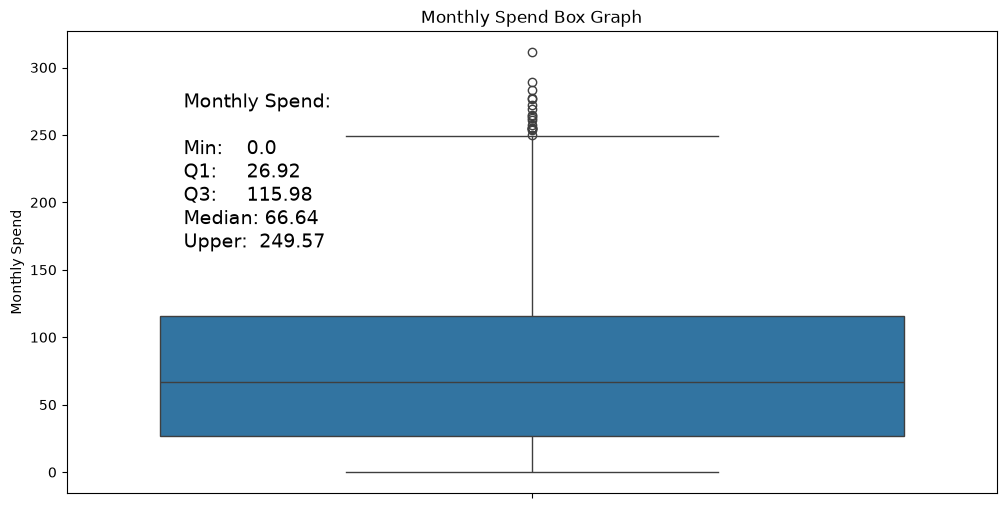

In [62]:
fig, ax = plt.subplots(figsize=(12,6))
p = sns.boxplot(
    subset.monthly_spend,
    ax=ax
)
id = subset.monthly_spend
q1 = np.quantile(id, 0.25)
q3 = np.quantile(id, 0.75)
iqr = q3-q1
min_val = id.min()
upper_bound = q3 + (1.5 * iqr)
median = id.median()
ax.text(
    -0.4, median*2.5,f"""
    Monthly Spend:
    
    Min:    {min_val}
    Q1:     {q1}
    Q3:     {q3}
    Median: {median}
    Upper:  {upper_bound}""",fontdict={"fontsize":14}
)
plt.ylabel('Monthly Spend')
plt.title('Monthly Spend Box Graph')
plt.show()

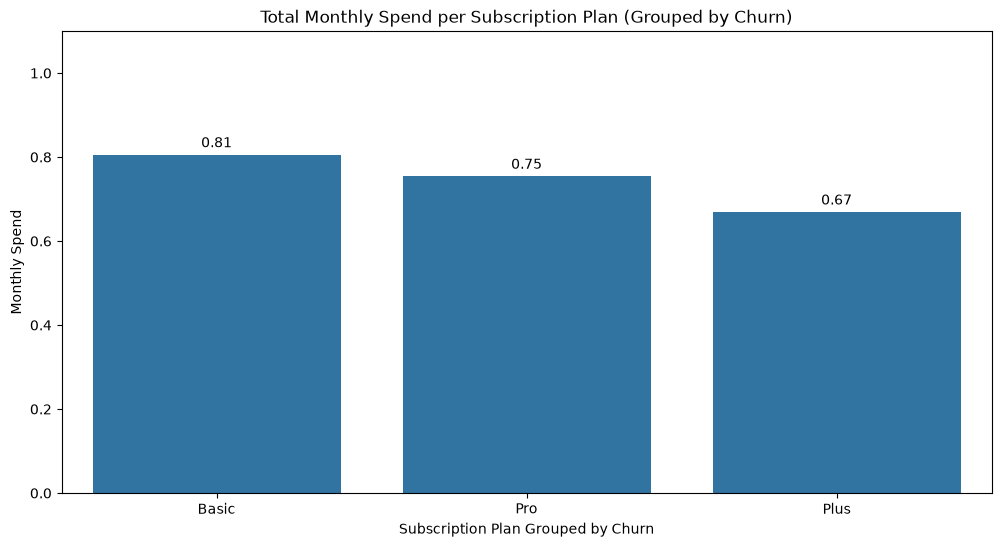

In [61]:
# Visualizing churn rate by monthly spend per subscription plan
fig, ax = plt.subplots(figsize=(12,6))
p = sns.barplot(
    x=subset.subscription_plan,
    y=subset.churn,
    ax=ax,
    errorbar=None
)
for p in p.patches:
    if p.get_height() > 0:
        height=p.get_height()
        ax.annotate(
            f'{height:.2f}',
            xy=(p.get_x()+p.get_width()/2,height),
            xytext=(0,3),
            textcoords='offset points',
            ha='center',
            va='bottom'
        )
plt.ylabel('Monthly Spend')
plt.ylim(0,1.1)
plt.xlabel('Subscription Plan Grouped by Churn')
plt.title('Total Monthly Spend per Subscription Plan (Grouped by Churn)')
plt.show()

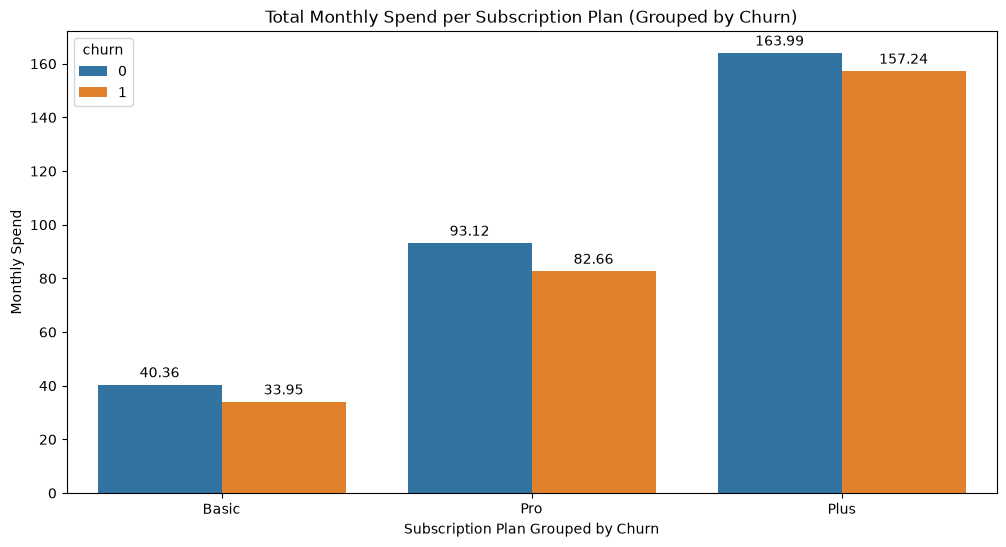

In [42]:
# Visualizing churn rate by monthly spend per subscription plan
fig, ax = plt.subplots(figsize=(12,6))
p = sns.barplot(
    x=subset.subscription_plan,
    y=subset.monthly_spend,
    hue=subset.churn,
    ax=ax,
    errorbar=None
)
for p in p.patches:
    if p.get_height() > 0:
        height=p.get_height()
        ax.annotate(
            f'{height:.2f}',
            xy=(p.get_x()+p.get_width()/2,height),
            xytext=(0,3),
            textcoords='offset points',
            ha='center',
            va='bottom'
        )
plt.ylabel('Monthly Spend')
plt.xlabel('Subscription Plan Grouped by Churn')
plt.title('Total Monthly Spend per Subscription Plan (Grouped by Churn)')
plt.show()

**_Total Monthly Spend per Subscription Plan Grouped by Churn_**
- Half of the customer spends between `$26.92` to `$115.98`, with average spend of `$66.64`
- All subscription plan shows elevated churn rate of `0.67 - 0.81`
- Retained customers spends more than churned customers across all subscription tiers
